## ML Fairness Detection

This notebook evaluates fairness in a baseline classification model by measuring performance disparities across sensitive demographic groups. The goal is to identify where and how the model fails — not to explain why.

In [3]:
## Import statements
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

### DATA CLEANING

In [4]:
data = pd.read_csv('../data/adult.csv')
data.head()

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K


In [5]:
data.replace('?', "unknown", inplace=True)

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,unknown,103497,Some-college,10,Never-married,unknown,Own-child,White,Female,0,0,30,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
48838,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
48839,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
48840,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K


In [6]:
# Detect and remove duplicates

data.duplicated().sum()
data.drop_duplicates(inplace=True)

In [7]:
data.describe(include='all')

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
count,48790.000000,48790,4.879000e+04,48790,48790.000000,48790,48790,48790,48790,48790,48790.000000,48790.000000,48790.000000,48790,48790
unique,NaN,9,NaN,16,NaN,7,15,6,5,2,NaN,NaN,NaN,42,2
top,NaN,Private,NaN,HS-grad,NaN,Married-civ-spouse,Prof-specialty,Husband,White,Male,NaN,NaN,NaN,United-States,<=50K
freq,NaN,33860,NaN,15770,NaN,22366,6165,19703,41714,32614,NaN,NaN,NaN,43792,37109
mean,38.652798,NaN,1.896690e+05,NaN,10.078807,NaN,NaN,NaN,NaN,NaN,1080.217688,87.595573,40.425886,NaN,NaN
std,13.708493,NaN,1.056172e+05,NaN,2.570046,NaN,NaN,NaN,NaN,NaN,7455.905921,403.209129,12.392729,NaN,NaN
min,17.000000,NaN,1.228500e+04,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,1.000000,NaN,NaN
25%,28.000000,NaN,1.175550e+05,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
50%,37.000000,NaN,1.781385e+05,NaN,10.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
75%,48.000000,NaN,2.376062e+05,NaN,12.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,45.000000,NaN,NaN


### CLASS DISTRIBUTION

The dataset exhibits significant class imbalance. Understanding this imbalance is crucial as it can impact model performance and fairness across demographic groups.

Class Distribution:
income
<=50K    37109
>50K     11681

Percentages:
<=50K: 76.06%
>50K: 23.94%

Imbalance Ratio: 3.18:1
Skew: The majority class is 3.18x larger than the minority class


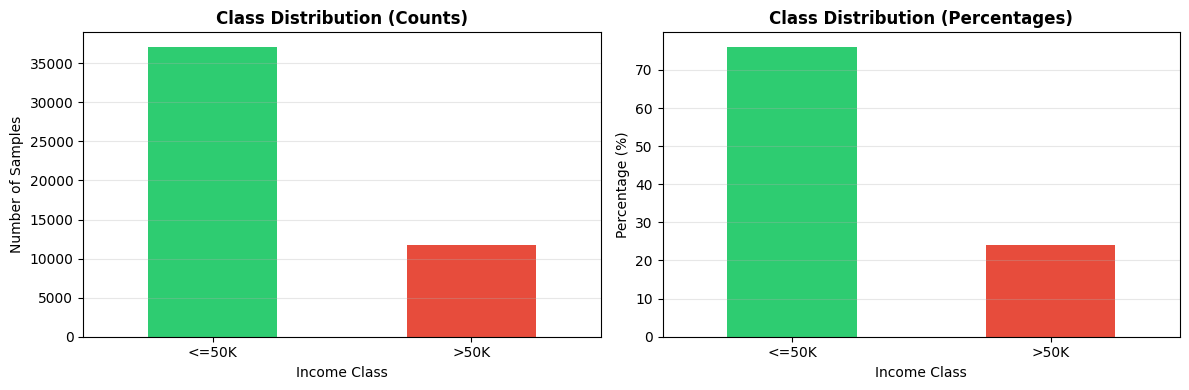

In [8]:
# Class distribution analysis
class_counts = data['income'].value_counts()
class_percentages = data['income'].value_counts(normalize=True) * 100

print("Class Distribution:")
print(f"{class_counts.to_string()}\n")
print(f"Percentages:")
for label, pct in class_percentages.items():
    print(f"{label}: {pct:.2f}%")

# Calculate imbalance ratio (skew)
minority_class = class_counts.min()
majority_class = class_counts.max()
imbalance_ratio = majority_class / minority_class

print(f"\nImbalance Ratio: {imbalance_ratio:.2f}:1")
print(f"Skew: The majority class is {imbalance_ratio:.2f}x larger than the minority class")

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Count plot
class_counts.plot(kind='bar', ax=axes[0], color=['#2ecc71', '#e74c3c'])
axes[0].set_title('Class Distribution (Counts)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Number of Samples')
axes[0].set_xlabel('Income Class')
axes[0].tick_params(axis='x', rotation=0)
axes[0].grid(axis='y', alpha=0.3)

# Percentage plot
class_percentages.plot(kind='bar', ax=axes[1], color=['#2ecc71', '#e74c3c'])
axes[1].set_title('Class Distribution (Percentages)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Percentage (%)')
axes[1].set_xlabel('Income Class')
axes[1].tick_params(axis='x', rotation=0)
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### SAMPLING

In [9]:
X = data.drop('income', axis=1)
y = data['income']

In [10]:
## Use label encoding for categorical features
label_encoders = {}
for column in X.select_dtypes(include=['object']).columns:
    le = LabelEncoder()
    X[column] = le.fit_transform(X[column])
    label_encoders[column] = le

/var/folders/2w/cb9k041n5tl8qwgh2d0bwbnw0000gp/T/ipykernel_3130/1607899653.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in X.select_dtypes(include=['object']).columns:


In [11]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)

### MODEL TRAINING

Training three models with identical setup:
- **Logistic Regression**
- **Random Forest**
- **AdaBoost**

All models use:
- Same features
- Same train/test split
- Same target variable
- Same decision threshold (0.2 for probability cutoff)

In [ ]:
THRESHOLD = 0.2

# Train all three models
models = {
    'Logistic Regression': LogisticRegression(max_iter=5000, solver='saga',random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'AdaBoost': AdaBoostClassifier(n_estimators=100,random_state=42)
}

# Store predictions for each model
predictions = {}

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)
    
    # Get probability predictions
    y_proba = model.predict_proba(X_test)[:, 1]  # Probability of positive class
    
    # Apply threshold
    y_pred = (y_proba >= THRESHOLD).astype(int)
    
    # Convert to original labels
    y_pred_labels = ['<=50K' if pred == 0 else '>50K' for pred in y_pred]
    
    # Store predictions
    predictions[name] = {
        'proba': y_proba,
        'pred': np.array(y_pred_labels),
        'model': model
    }
    
    print(f"  ✓ {name} trained successfully\n")

Training Logistic Regression...
  ✓ Logistic Regression trained successfully

Training Random Forest...
  ✓ Random Forest trained successfully

Training AdaBoost...
  ✓ AdaBoost trained successfully



### OVERALL MODEL PERFORMANCE

Comparing standard classification metrics across all three models

### FAIRNESS ANALYSIS

For each model and each sensitive demographic group, we compute:
- **Approval Rate**: Proportion of positive predictions (>50K)
- **False Positive Rate (FPR)**: Proportion of negative cases incorrectly classified as positive
- **False Negative Rate (FNR)**: Proportion of positive cases incorrectly classified as negative

In [13]:
# Prepare test data with decoded sensitive attributes
test_data_base = X_test.copy()
test_data_base['actual'] = y_test.values
test_data_base['gender'] = label_encoders['gender'].inverse_transform(X_test['gender'])
test_data_base['race'] = label_encoders['race'].inverse_transform(X_test['race'])

# Function to calculate fairness metrics by group
def calculate_fairness_metrics(y_true, y_pred, group_data, group_col):
    """
    Calculate approval rate, FPR, and FNR for each group
    """
    metrics = []
    
    for group in group_data[group_col].unique():
        mask = group_data[group_col] == group
        y_true_group = y_true[mask]
        y_pred_group = y_pred[mask]
        
        # Approval rate
        approval_rate = (y_pred_group == '>50K').sum() / len(y_pred_group)
        
        # FPR: False Positives / (False Positives + True Negatives)
        # FP = predicted positive but actually negative
        fp = ((y_pred_group == '>50K') & (y_true_group == '<=50K')).sum()
        tn = ((y_pred_group == '<=50K') & (y_true_group == '<=50K')).sum()
        fpr = fp / (fp + tn) if (fp + tn) > 0 else 0
        
        # FNR: False Negatives / (False Negatives + True Positives)
        # FN = predicted negative but actually positive
        fn = ((y_pred_group == '<=50K') & (y_true_group == '>50K')).sum()
        tp = ((y_pred_group == '>50K') & (y_true_group == '>50K')).sum()
        fnr = fn / (fn + tp) if (fn + tp) > 0 else 0
        
        metrics.append({
            'Group': group,
            'Sample Size': mask.sum(),
            'Approval Rate': approval_rate,
            'FPR': fpr,
            'FNR': fnr
        })
    
    return pd.DataFrame(metrics)

# Calculate metrics for all models and groups
all_metrics = {}

for model_name, pred_data in predictions.items():
    y_pred = pred_data['pred']
    
    # Gender metrics
    gender_metrics = calculate_fairness_metrics(y_test.values, y_pred, test_data_base, 'gender')
    
    # Race metrics
    race_metrics = calculate_fairness_metrics(y_test.values, y_pred, test_data_base, 'race')
    
    all_metrics[model_name] = {
        'gender': gender_metrics,
        'race': race_metrics
    }

print("Fairness metrics calculated for all models ✓")

Fairness metrics calculated for all models ✓


#### Metrics Summary by Model

In [14]:
# Display metrics for each model
for model_name in all_metrics.keys():
    print(f"\n{'='*70}")
    print(f"  {model_name.upper()}")
    print(f"{'='*70}")
    
    print("\n📊 GENDER METRICS:")
    print(all_metrics[model_name]['gender'].to_string(index=False))
    
    print("\n📊 RACE METRICS:")
    print(all_metrics[model_name]['race'].to_string(index=False))


  LOGISTIC REGRESSION

📊 GENDER METRICS:
 Group  Sample Size  Approval Rate      FPR      FNR
  Male         6532       0.710502 0.677264 0.212582
Female         3226       0.734346 0.721084 0.155620

📊 RACE METRICS:
             Group  Sample Size  Approval Rate      FPR      FNR
             White         8314       0.732620 0.708944 0.197724
             Black          984       0.563008 0.551044 0.352459
Amer-Indian-Eskimo           82       0.865854 0.866667 0.142857
             Other           90       0.655556 0.637500 0.200000
Asian-Pac-Islander          288       0.815972 0.802752 0.142857

  RANDOM FOREST

📊 GENDER METRICS:
 Group  Sample Size  Approval Rate      FPR      FNR
  Male         6532       0.488518 0.319009 0.119229
Female         3226       0.179789 0.106982 0.216138

📊 RACE METRICS:
             Group  Sample Size  Approval Rate      FPR      FNR
             White         8314       0.405822 0.249476 0.134187
             Black          984       0.223577 0.1

#### Visualization: Approval Rate by Group

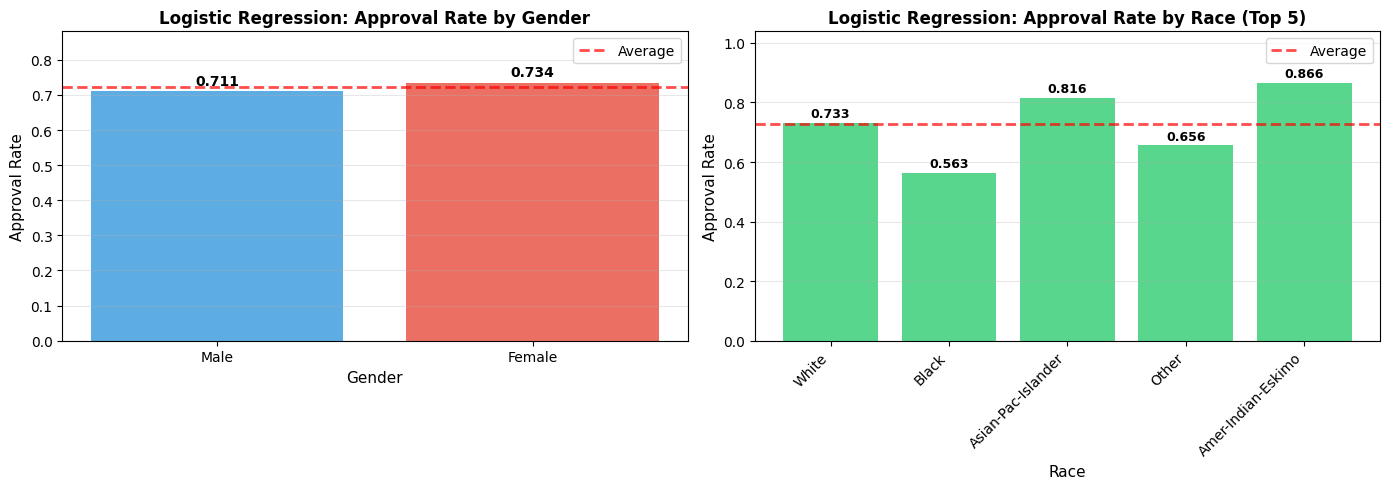

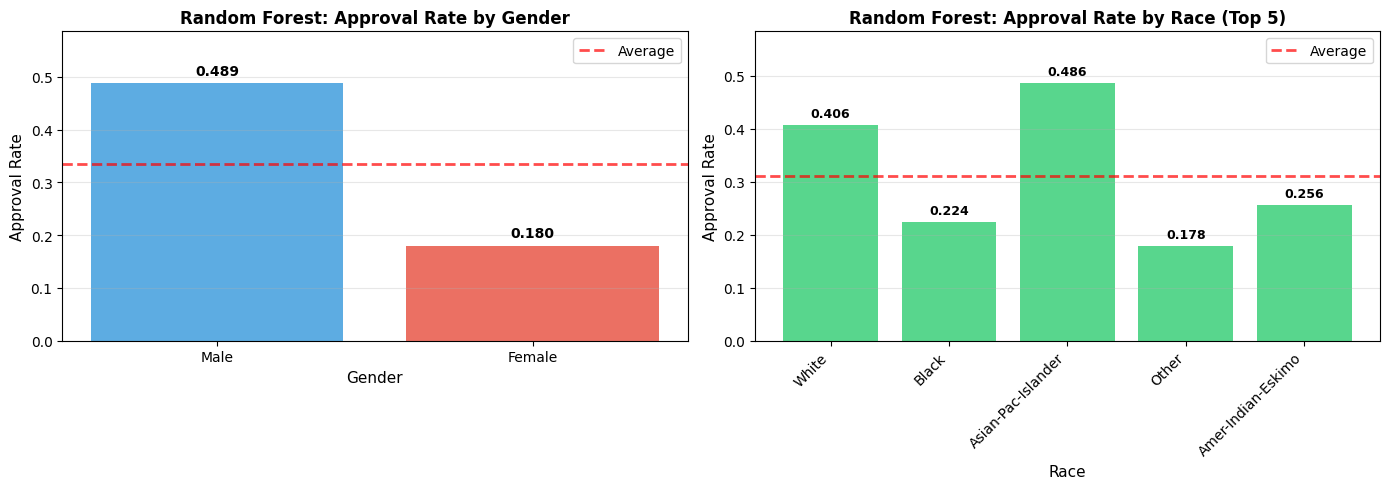

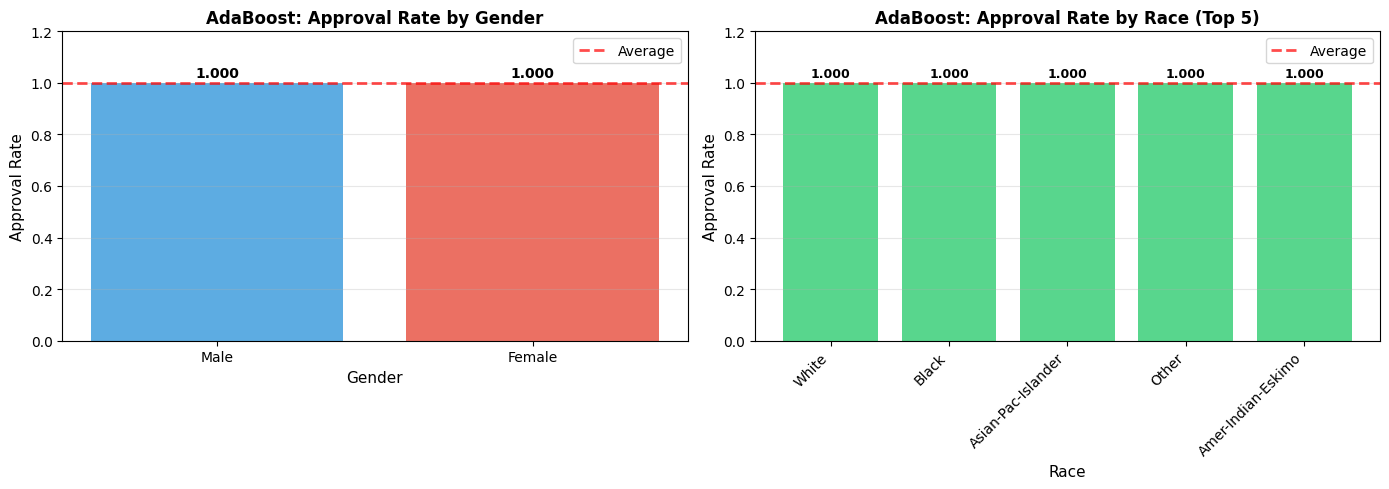

In [15]:
# Plot Approval Rate by Group for each model
for model_name in all_metrics.keys():
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Gender approval rate
    gender_df = all_metrics[model_name]['gender']
    x_pos = np.arange(len(gender_df))
    axes[0].bar(x_pos, gender_df['Approval Rate'], color=['#3498db', '#e74c3c'], alpha=0.8)
    axes[0].set_xticks(x_pos)
    axes[0].set_xticklabels(gender_df['Group'], rotation=0)
    axes[0].set_ylabel('Approval Rate', fontsize=11)
    axes[0].set_xlabel('Gender', fontsize=11)
    axes[0].set_title(f'{model_name}: Approval Rate by Gender', fontsize=12, fontweight='bold')
    axes[0].set_ylim([0, max(gender_df['Approval Rate']) * 1.2])
    axes[0].axhline(y=gender_df['Approval Rate'].mean(), color='red', linestyle='--', 
                    linewidth=2, label='Average', alpha=0.7)
    axes[0].legend()
    axes[0].grid(axis='y', alpha=0.3)
    
    # Add values on bars
    for i, v in enumerate(gender_df['Approval Rate']):
        axes[0].text(i, v + 0.01, f'{v:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
    
    # Race approval rate (top 5 by sample size)
    race_df = all_metrics[model_name]['race'].nlargest(5, 'Sample Size')
    x_pos = np.arange(len(race_df))
    axes[1].bar(x_pos, race_df['Approval Rate'], color='#2ecc71', alpha=0.8)
    axes[1].set_xticks(x_pos)
    axes[1].set_xticklabels(race_df['Group'], rotation=45, ha='right')
    axes[1].set_ylabel('Approval Rate', fontsize=11)
    axes[1].set_xlabel('Race', fontsize=11)
    axes[1].set_title(f'{model_name}: Approval Rate by Race (Top 5)', fontsize=12, fontweight='bold')
    axes[1].set_ylim([0, max(race_df['Approval Rate']) * 1.2])
    axes[1].axhline(y=all_metrics[model_name]['race']['Approval Rate'].mean(), 
                    color='red', linestyle='--', linewidth=2, label='Average', alpha=0.7)
    axes[1].legend()
    axes[1].grid(axis='y', alpha=0.3)
    
    # Add values on bars
    for i, v in enumerate(race_df['Approval Rate']):
        axes[1].text(i, v + 0.01, f'{v:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
    
    plt.tight_layout()
    plt.show()
    print()

#### Visualization: False Positive Rate (FPR) by Group

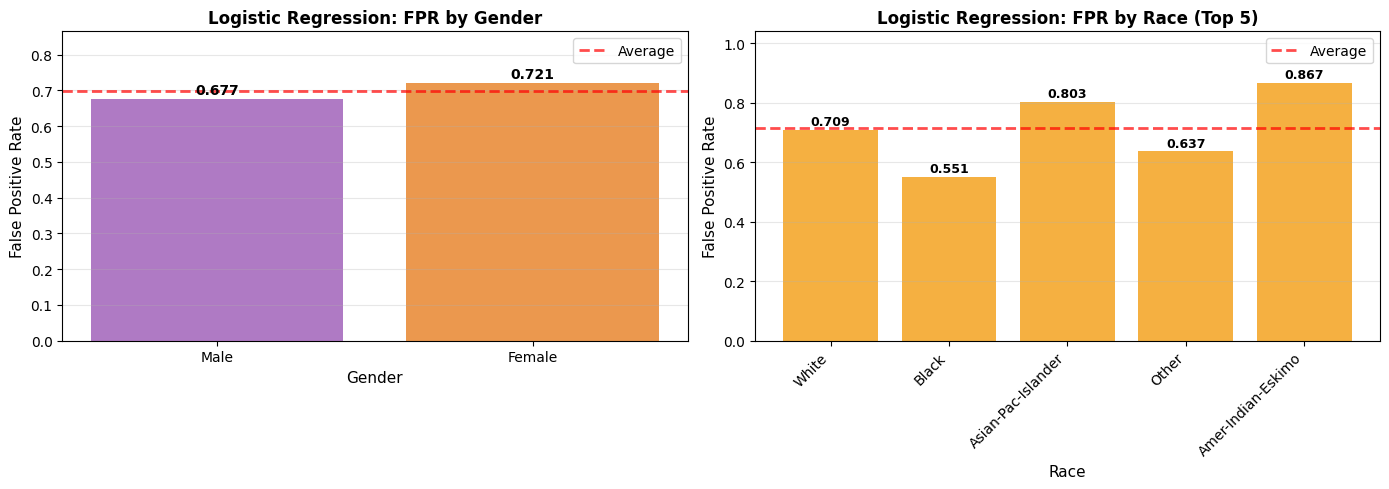

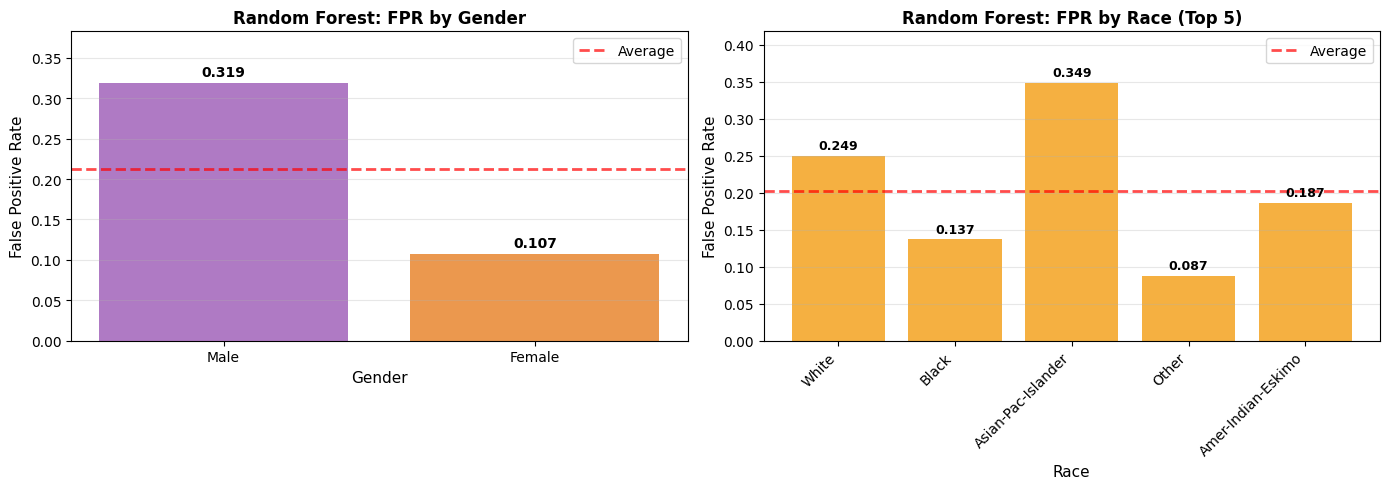

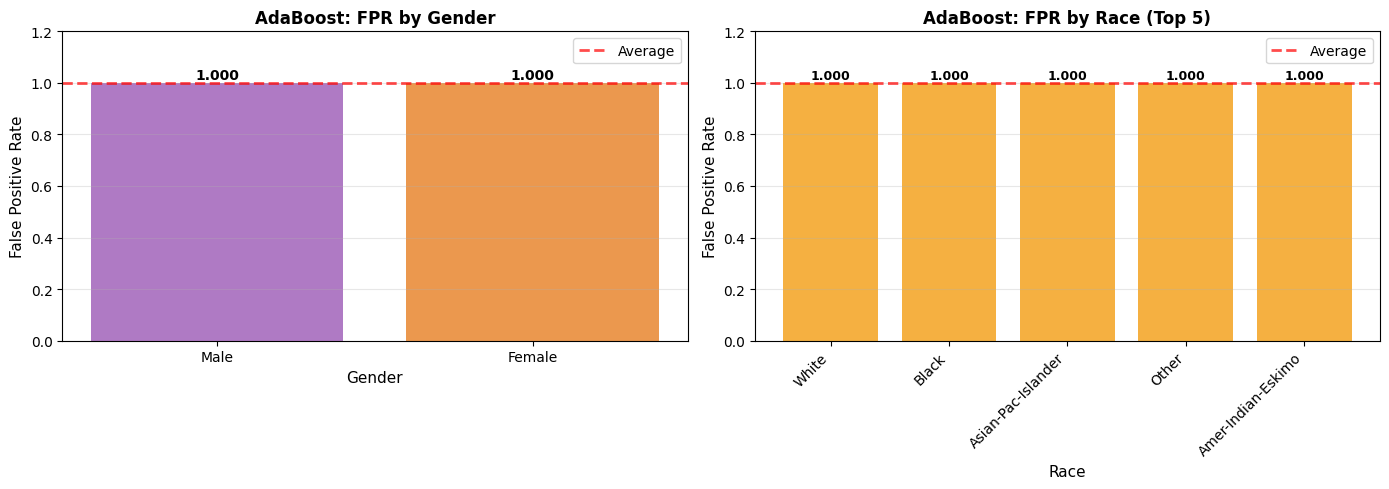

In [16]:
# Plot FPR by Group for each model
for model_name in all_metrics.keys():
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Gender FPR
    gender_df = all_metrics[model_name]['gender']
    x_pos = np.arange(len(gender_df))
    axes[0].bar(x_pos, gender_df['FPR'], color=['#9b59b6', '#e67e22'], alpha=0.8)
    axes[0].set_xticks(x_pos)
    axes[0].set_xticklabels(gender_df['Group'], rotation=0)
    axes[0].set_ylabel('False Positive Rate', fontsize=11)
    axes[0].set_xlabel('Gender', fontsize=11)
    axes[0].set_title(f'{model_name}: FPR by Gender', fontsize=12, fontweight='bold')
    axes[0].set_ylim([0, max(gender_df['FPR']) * 1.2 if max(gender_df['FPR']) > 0 else 0.1])
    axes[0].axhline(y=gender_df['FPR'].mean(), color='red', linestyle='--', 
                    linewidth=2, label='Average', alpha=0.7)
    axes[0].legend()
    axes[0].grid(axis='y', alpha=0.3)
    
    # Add values on bars
    for i, v in enumerate(gender_df['FPR']):
        axes[0].text(i, v + 0.005, f'{v:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
    
    # Race FPR (top 5 by sample size)
    race_df = all_metrics[model_name]['race'].nlargest(5, 'Sample Size')
    x_pos = np.arange(len(race_df))
    axes[1].bar(x_pos, race_df['FPR'], color='#f39c12', alpha=0.8)
    axes[1].set_xticks(x_pos)
    axes[1].set_xticklabels(race_df['Group'], rotation=45, ha='right')
    axes[1].set_ylabel('False Positive Rate', fontsize=11)
    axes[1].set_xlabel('Race', fontsize=11)
    axes[1].set_title(f'{model_name}: FPR by Race (Top 5)', fontsize=12, fontweight='bold')
    axes[1].set_ylim([0, max(race_df['FPR']) * 1.2 if max(race_df['FPR']) > 0 else 0.1])
    axes[1].axhline(y=all_metrics[model_name]['race']['FPR'].mean(), 
                    color='red', linestyle='--', linewidth=2, label='Average', alpha=0.7)
    axes[1].legend()
    axes[1].grid(axis='y', alpha=0.3)
    
    # Add values on bars
    for i, v in enumerate(race_df['FPR']):
        axes[1].text(i, v + 0.005, f'{v:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
    
    plt.tight_layout()
    plt.show()
    print()

#### Visualization: False Negative Rate (FNR) by Group

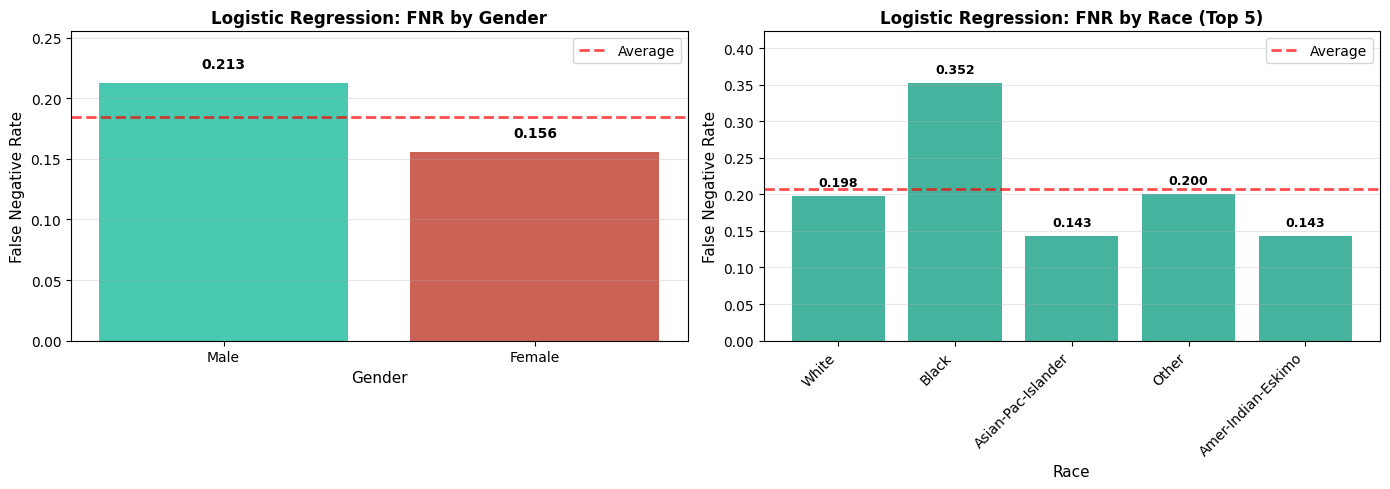

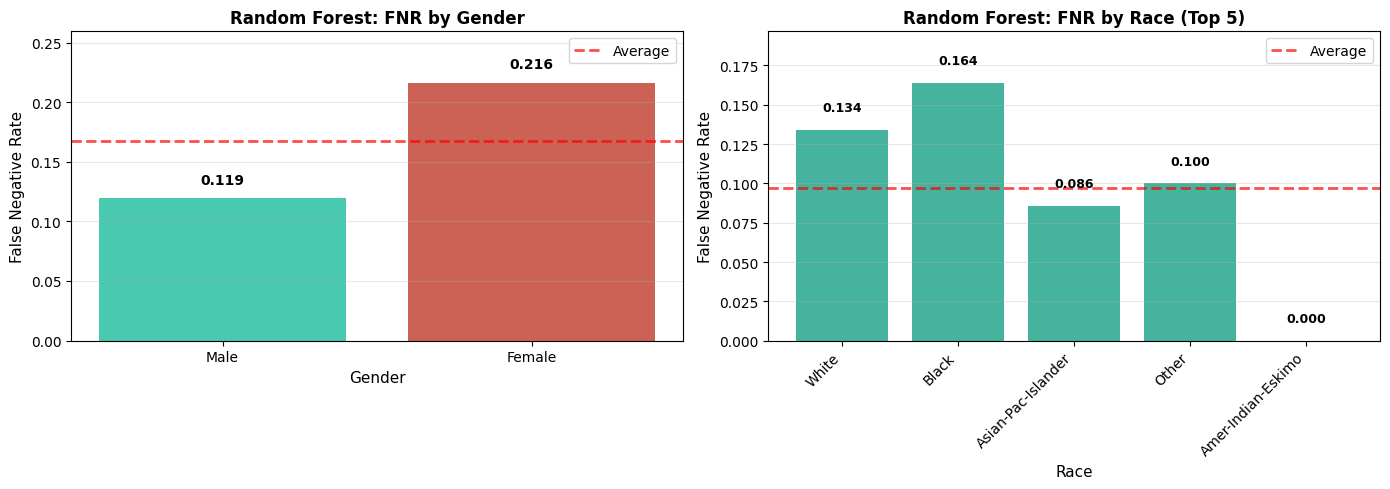

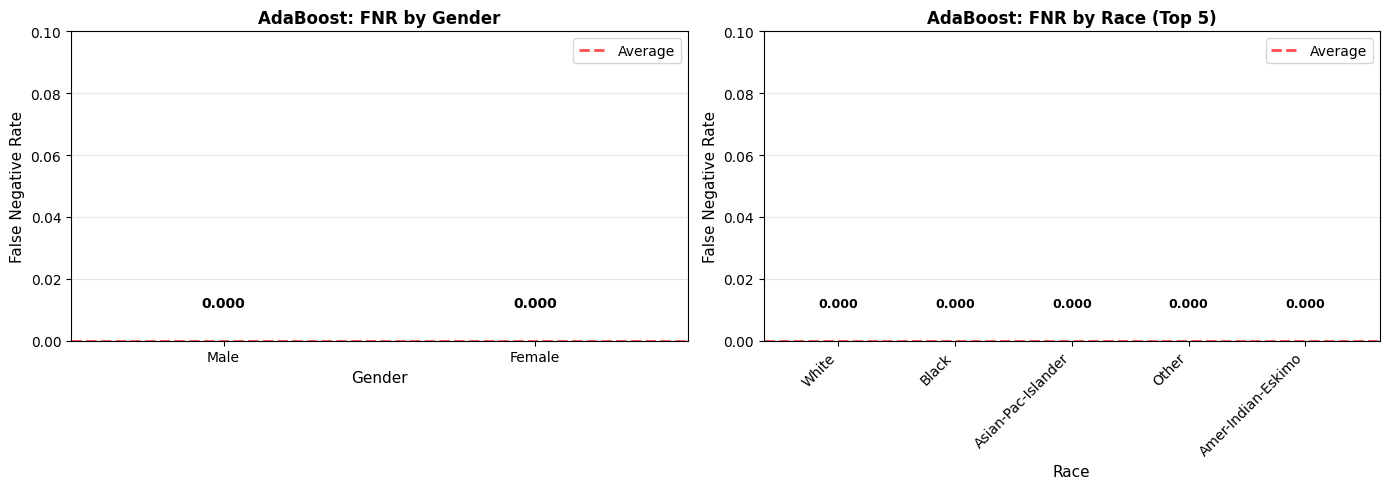

In [17]:
# Plot FNR by Group for each model
for model_name in all_metrics.keys():
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Gender FNR
    gender_df = all_metrics[model_name]['gender']
    x_pos = np.arange(len(gender_df))
    axes[0].bar(x_pos, gender_df['FNR'], color=['#1abc9c', '#c0392b'], alpha=0.8)
    axes[0].set_xticks(x_pos)
    axes[0].set_xticklabels(gender_df['Group'], rotation=0)
    axes[0].set_ylabel('False Negative Rate', fontsize=11)
    axes[0].set_xlabel('Gender', fontsize=11)
    axes[0].set_title(f'{model_name}: FNR by Gender', fontsize=12, fontweight='bold')
    axes[0].set_ylim([0, max(gender_df['FNR']) * 1.2 if max(gender_df['FNR']) > 0 else 0.1])
    axes[0].axhline(y=gender_df['FNR'].mean(), color='red', linestyle='--', 
                    linewidth=2, label='Average', alpha=0.7)
    axes[0].legend()
    axes[0].grid(axis='y', alpha=0.3)
    
    # Add values on bars
    for i, v in enumerate(gender_df['FNR']):
        axes[0].text(i, v + 0.01, f'{v:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
    
    # Race FNR (top 5 by sample size)
    race_df = all_metrics[model_name]['race'].nlargest(5, 'Sample Size')
    x_pos = np.arange(len(race_df))
    axes[1].bar(x_pos, race_df['FNR'], color='#16a085', alpha=0.8)
    axes[1].set_xticks(x_pos)
    axes[1].set_xticklabels(race_df['Group'], rotation=45, ha='right')
    axes[1].set_ylabel('False Negative Rate', fontsize=11)
    axes[1].set_xlabel('Race', fontsize=11)
    axes[1].set_title(f'{model_name}: FNR by Race (Top 5)', fontsize=12, fontweight='bold')
    axes[1].set_ylim([0, max(race_df['FNR']) * 1.2 if max(race_df['FNR']) > 0 else 0.1])
    axes[1].axhline(y=all_metrics[model_name]['race']['FNR'].mean(), 
                    color='red', linestyle='--', linewidth=2, label='Average', alpha=0.7)
    axes[1].legend()
    axes[1].grid(axis='y', alpha=0.3)
    
    # Add values on bars
    for i, v in enumerate(race_df['FNR']):
        axes[1].text(i, v + 0.01, f'{v:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
    
    plt.tight_layout()
    plt.show()
    print()

#### Comparative Analysis: All Models Side-by-Side

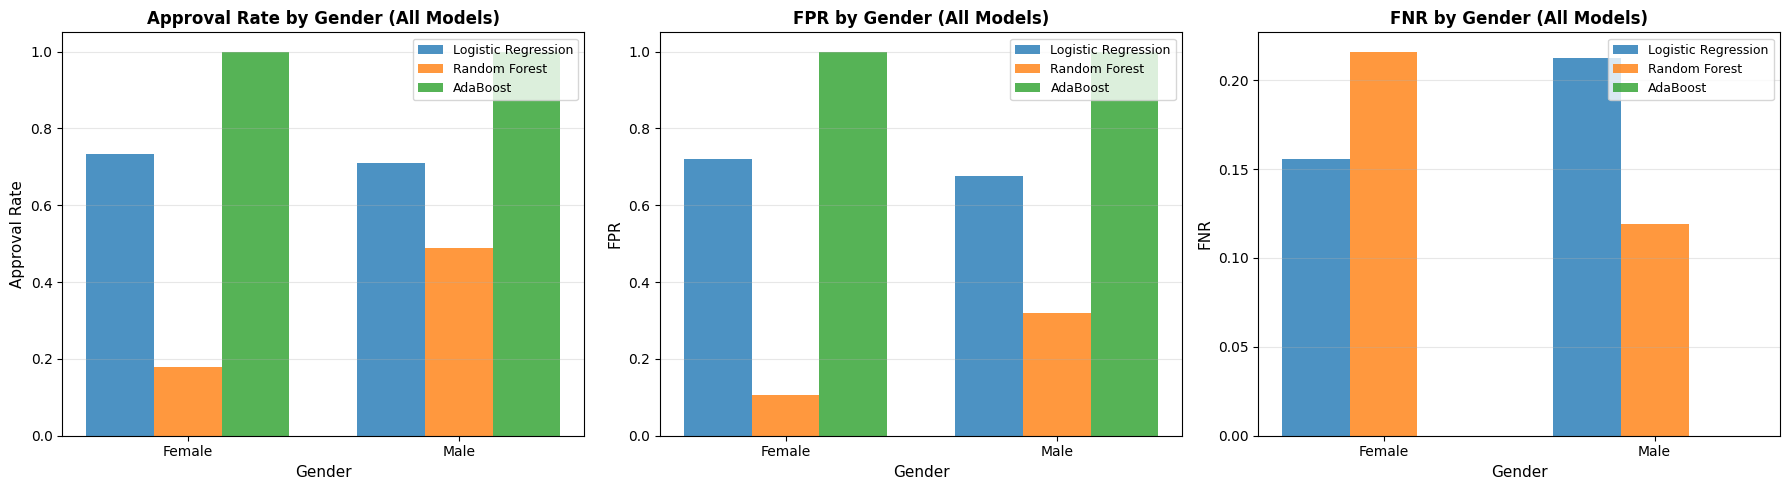

In [18]:
# Compare all models for gender groups
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

metrics_to_plot = ['Approval Rate', 'FPR', 'FNR']
colors = ['#3498db', '#e74c3c']

for idx, metric in enumerate(metrics_to_plot):
    ax = axes[idx]
    
    # Prepare data for all models
    x_offset = 0
    bar_width = 0.25
    
    for model_idx, (model_name, metrics) in enumerate(all_metrics.items()):
        gender_df = metrics['gender'].sort_values('Group')
        x_pos = np.arange(len(gender_df)) + model_idx * bar_width
        
        bars = ax.bar(x_pos, gender_df[metric], bar_width, 
                     label=model_name, alpha=0.8)
        
    ax.set_xticks(np.arange(len(gender_df)) + bar_width)
    ax.set_xticklabels(gender_df['Group'])
    ax.set_ylabel(metric, fontsize=11)
    ax.set_xlabel('Gender', fontsize=11)
    ax.set_title(f'{metric} by Gender (All Models)', fontsize=12, fontweight='bold')
    ax.legend(fontsize=9)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [19]:
# Calculate overall performance metrics for all models
performance_results = []

for model_name, pred_data in predictions.items():
    y_pred = pred_data['pred']
    
    # Calculate metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, pos_label='>50K')
    rec = recall_score(y_test, y_pred, pos_label='>50K')
    f1 = f1_score(y_test, y_pred, pos_label='>50K')
    
    performance_results.append({
        'Model': model_name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1 Score': f1
    })

# Create DataFrame
performance_df = pd.DataFrame(performance_results)

# Display results
print("=" * 70)
print("OVERALL MODEL PERFORMANCE COMPARISON")
print("=" * 70)
print(performance_df.to_string(index=False))
print("\nBest performing model by metric:")
for metric in ['Accuracy', 'Precision', 'Recall', 'F1 Score']:
    best_model = performance_df.loc[performance_df[metric].idxmax(), 'Model']
    best_score = performance_df[metric].max()
    print(f"  {metric:12s}: {best_model:20s} ({best_score:.4f})")

OVERALL MODEL PERFORMANCE COMPARISON
              Model  Accuracy  Precision   Recall  F1 Score
Logistic Regression  0.422218   0.263195 0.795945  0.395583
      Random Forest  0.787559   0.532485 0.866264  0.659550
           AdaBoost  0.237549   0.237549 1.000000  0.383902

Best performing model by metric:
  Accuracy    : Random Forest        (0.7876)
  Precision   : Random Forest        (0.5325)
  Recall      : AdaBoost             (1.0000)
  F1 Score    : Random Forest        (0.6596)


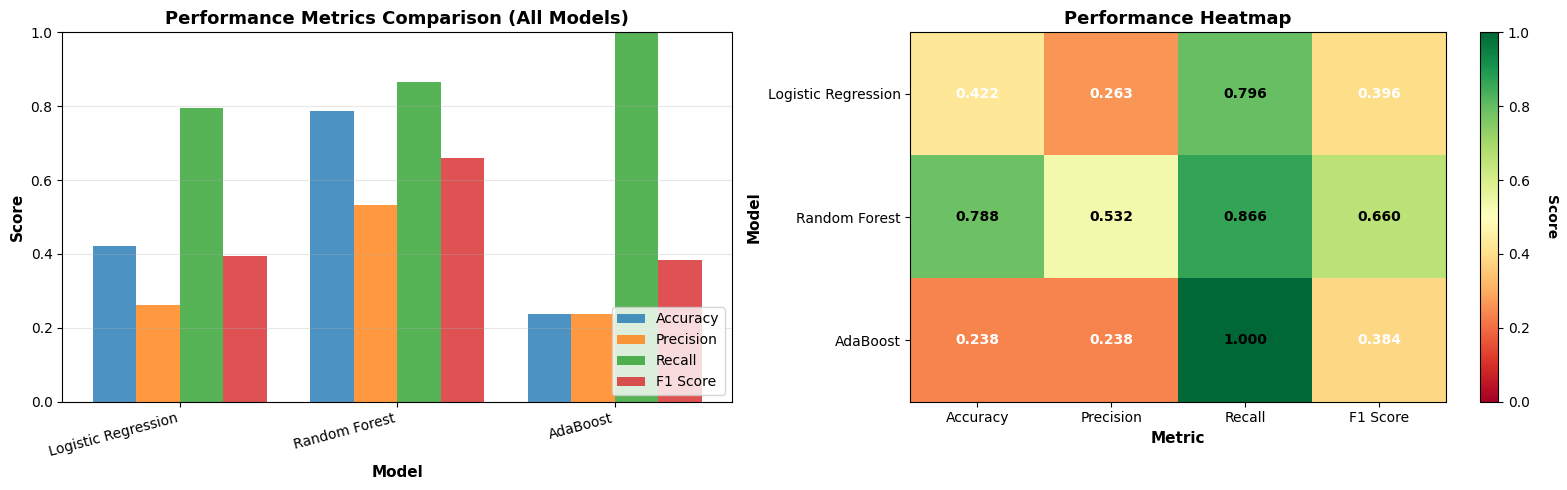

In [20]:
# Visualize model performance comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Bar plot of all metrics
metrics_plot = performance_df.set_index('Model')[['Accuracy', 'Precision', 'Recall', 'F1 Score']]
x = np.arange(len(metrics_plot))
width = 0.2

for i, metric in enumerate(['Accuracy', 'Precision', 'Recall', 'F1 Score']):
    offset = (i - 1.5) * width
    axes[0].bar(x + offset, metrics_plot[metric], width, label=metric, alpha=0.8)

axes[0].set_xlabel('Model', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Score', fontsize=11, fontweight='bold')
axes[0].set_title('Performance Metrics Comparison (All Models)', fontsize=13, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(metrics_plot.index, rotation=15, ha='right')
axes[0].legend(loc='lower right', fontsize=10)
axes[0].grid(axis='y', alpha=0.3)
axes[0].set_ylim([0, 1])

# Heatmap of performance
metrics_heatmap = performance_df.set_index('Model')[['Accuracy', 'Precision', 'Recall', 'F1 Score']]
im = axes[1].imshow(metrics_heatmap.values, cmap='RdYlGn', aspect='auto', vmin=0, vmax=1)

# Add colorbar
cbar = plt.colorbar(im, ax=axes[1])
cbar.set_label('Score', rotation=270, labelpad=20, fontsize=10, fontweight='bold')

# Set ticks and labels
axes[1].set_xticks(np.arange(len(metrics_heatmap.columns)))
axes[1].set_yticks(np.arange(len(metrics_heatmap.index)))
axes[1].set_xticklabels(metrics_heatmap.columns, fontsize=10)
axes[1].set_yticklabels(metrics_heatmap.index, fontsize=10)
axes[1].set_xlabel('Metric', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Model', fontsize=11, fontweight='bold')
axes[1].set_title('Performance Heatmap', fontsize=13, fontweight='bold')

# Add text annotations
for i in range(len(metrics_heatmap.index)):
    for j in range(len(metrics_heatmap.columns)):
        value = metrics_heatmap.values[i, j]
        color = 'white' if value < 0.5 else 'black'
        axes[1].text(j, i, f'{value:.3f}', ha='center', va='center', 
                    color=color, fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

## Conclusion

1. The jsfdksj
2. skdfjslkf
3. sdkfhsd